# Tewhey HepG2 MPRA versus liver eQTL

Compare reported MPRA and eQTL effects across GTEx significant associations and FINEMAP/SuSiE subsets. These are descriptive comparisons, not independent-variant significance tests.

## Inputs and interpretation

The MPRA input is the existing processed HepG2 table, using log2Skew and its supplied emVar labels. Original processing provenance and the emVar definition have not yet been recovered.

GTEx significant pairs: [syn69058503.1](https://www.synapse.org/Synapse:syn69058503.1). Fine-mapping: local GTEx table, filtered to Liver and PIP>0.1. See `../README.md` for input filenames and provenance gaps.

**Effect direction remains provisional:** we audit A1/A2 or allele1/allele2 against SPDI, but have not independently recovered the source definitions of each effect column. No automatic sign flips are applied.

## Configuration

Set `IAWG_DATA_DIR` to the directory containing the required input files. Figures and aggregate summaries are written within this contributor directory.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import pandas as pd

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'zychu912']
ROOT = next((p for p in candidates if (p / 'notebooks' / 'eqtl_mpra.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the contributor directory or notebooks directory.')
sys.path.insert(0, str(ROOT / 'notebooks'))
from eqtl_mpra import load_eqtls, load_mpra, compare, plot_panels, describe_run

DATA_DIR = Path(os.environ.get('IAWG_DATA_DIR', str(ROOT / 'data'))).expanduser()
PIP_THRESHOLD = 0.1
MPRA_Q_THRESHOLD = 0.05
DATASET = 'tewhey'

## Load and validate

Validate required columns, numeric/boolean values and allele metadata; report exclusions and duplicate variant keys. Distinct MPRA records are retained because repeated SPDI identifiers may represent different constructs or libraries.

In [2]:
eqtls, eqtl_audit = load_eqtls(DATA_DIR, pip_threshold=PIP_THRESHOLD)
mpra, mpra_audit = load_mpra(DATA_DIR, DATASET, q_threshold=MPRA_Q_THRESHOLD)
display(pd.DataFrame(eqtl_audit['eqtl_inputs']))
display(pd.DataFrame([mpra_audit]))
print('Nonfinite eQTL rows excluded:', eqtl_audit['excluded_nonfinite_gtex'],
      eqtl_audit['excluded_nonfinite_liver_finemap'])

,dataset,rows,unique_variants,unique_variant_gene_pairs,allele_metadata_counts
0,GTEx,931743,584404,931743,"{""matches_spdi_order"": 931743}"
1,FINEMAP,8950,8361,8950,"{""matches_spdi_order"": 8674, ""non_snv_or_unres..."
2,SUSIE,6249,5884,6249,"{""matches_spdi_order"": 6065, ""non_snv_or_unres..."


,dataset,rows,unique_variants,duplicated_variant_keys,highlight_rows,excluded_nonfinite,allele_metadata_counts
0,tewhey,287368,280225,7143,15652,0,"{'matches_spdi_order': 207362, 'snv_mismatch':..."


Nonfinite eQTL rows excluded: 0 0


## Select associations and join

For each variant, “top” chooses the smallest nominal p-value (GTEx) or largest PIP (FINEMAP/SuSiE), breaking ties by gene ID, effect, then source row ID. “All” retains every eligible association.

Each point is an **MPRA record × eQTL association match**. We report matched rows, unique variants, unique variant–gene pairs and MPRA records separately. Row-level correlations are descriptive: repeated records and linkage are not independent samples, so no independence-based p-values are reported.

The summary also includes a sensitivity subset requiring both inputs’ allele fields to match the SPDI order. This flags representation issues (including unresolved indels); it does **not** establish that the effect directions are harmonized. The primary plots retain all eligible records.

In [3]:
panels, summary = compare(eqtls, mpra, DATASET)
display(summary.round({'pearson_r': 4, 'spearman_rho': 4, 'concordance': 4}))

,dataset,version,eqtl,selection,subset,n_rows,n_unique_variants,n_variant_gene_pairs,n_mpra_records,pearson_r,spearman_rho,concordance,n_zero_effect_rows
0,tewhey,all_records,GTEx,top,all,73145,69885,69885,73145,0.0141,0.0099,0.5019,0
1,tewhey,all_records,GTEx,top,highlighted,4303,4181,4181,4303,0.0987,0.0983,0.5438,0
2,tewhey,all_records,GTEx,top,metadata_consistent,68797,66136,66136,68797,0.0130,0.0097,0.5018,0
3,tewhey,all_records,GTEx,top,highlighted_metadata_consistent,4081,3975,3975,4081,0.1002,0.0996,0.5447,0
4,tewhey,all_records,GTEx,all,all,116765,69885,111231,73145,0.0132,0.0096,0.5015,0
5,tewhey,all_records,GTEx,all,highlighted,6755,4181,6562,4303,0.0766,0.0714,0.5297,0
6,tewhey,all_records,GTEx,all,metadata_consistent,110986,66136,106339,68797,0.0117,0.0091,0.5013,0
7,tewhey,all_records,GTEx,all,highlighted_metadata_consistent,6475,3975,6305,4081,0.0777,0.0725,0.5297,0
8,tewhey,all_records,FINEMAP,top,all,6254,5750,5750,6254,0.0929,0.0796,0.5278,0
9,tewhey,all_records,FINEMAP,top,highlighted,508,481,481,508,0.3240,0.2937,0.6614,0


## Plot and record provenance

The same mask defines highlighted points and subgroup statistics. Concordance requires two nonzero effects with the same sign; zero-effect rows remain in the denominator. Figures are exported as 300 DPI PNG. Summary tables and the input hashes, parameters and package versions are retained directly in this notebook.

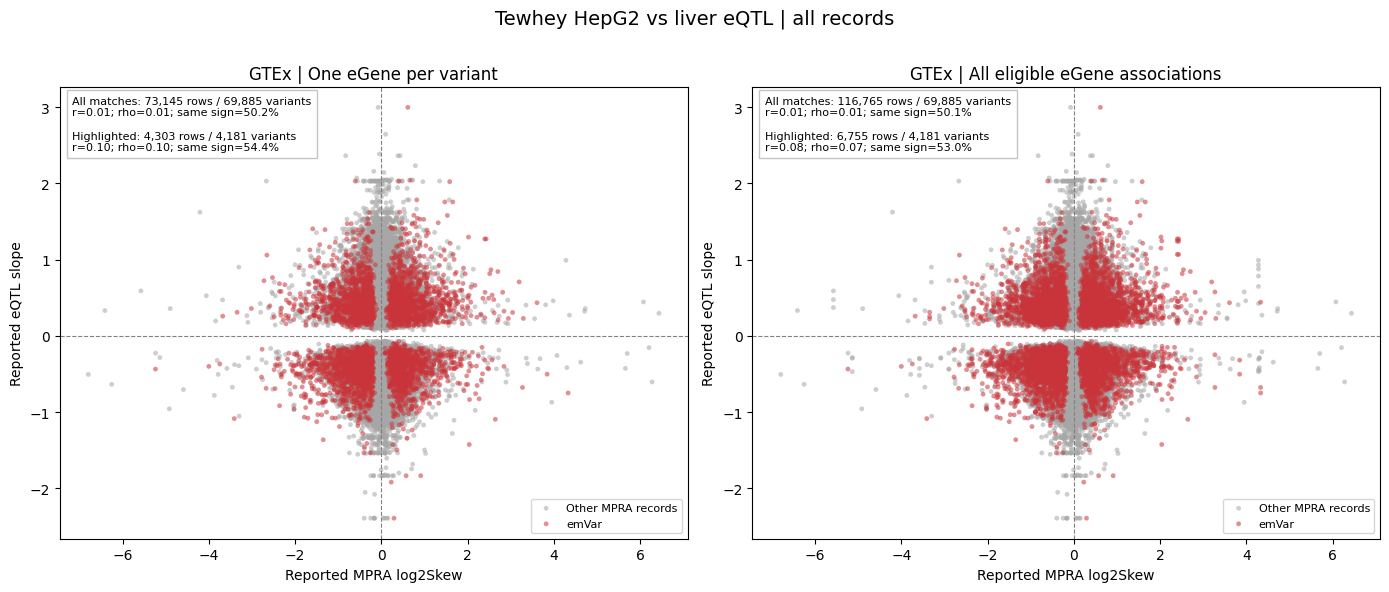

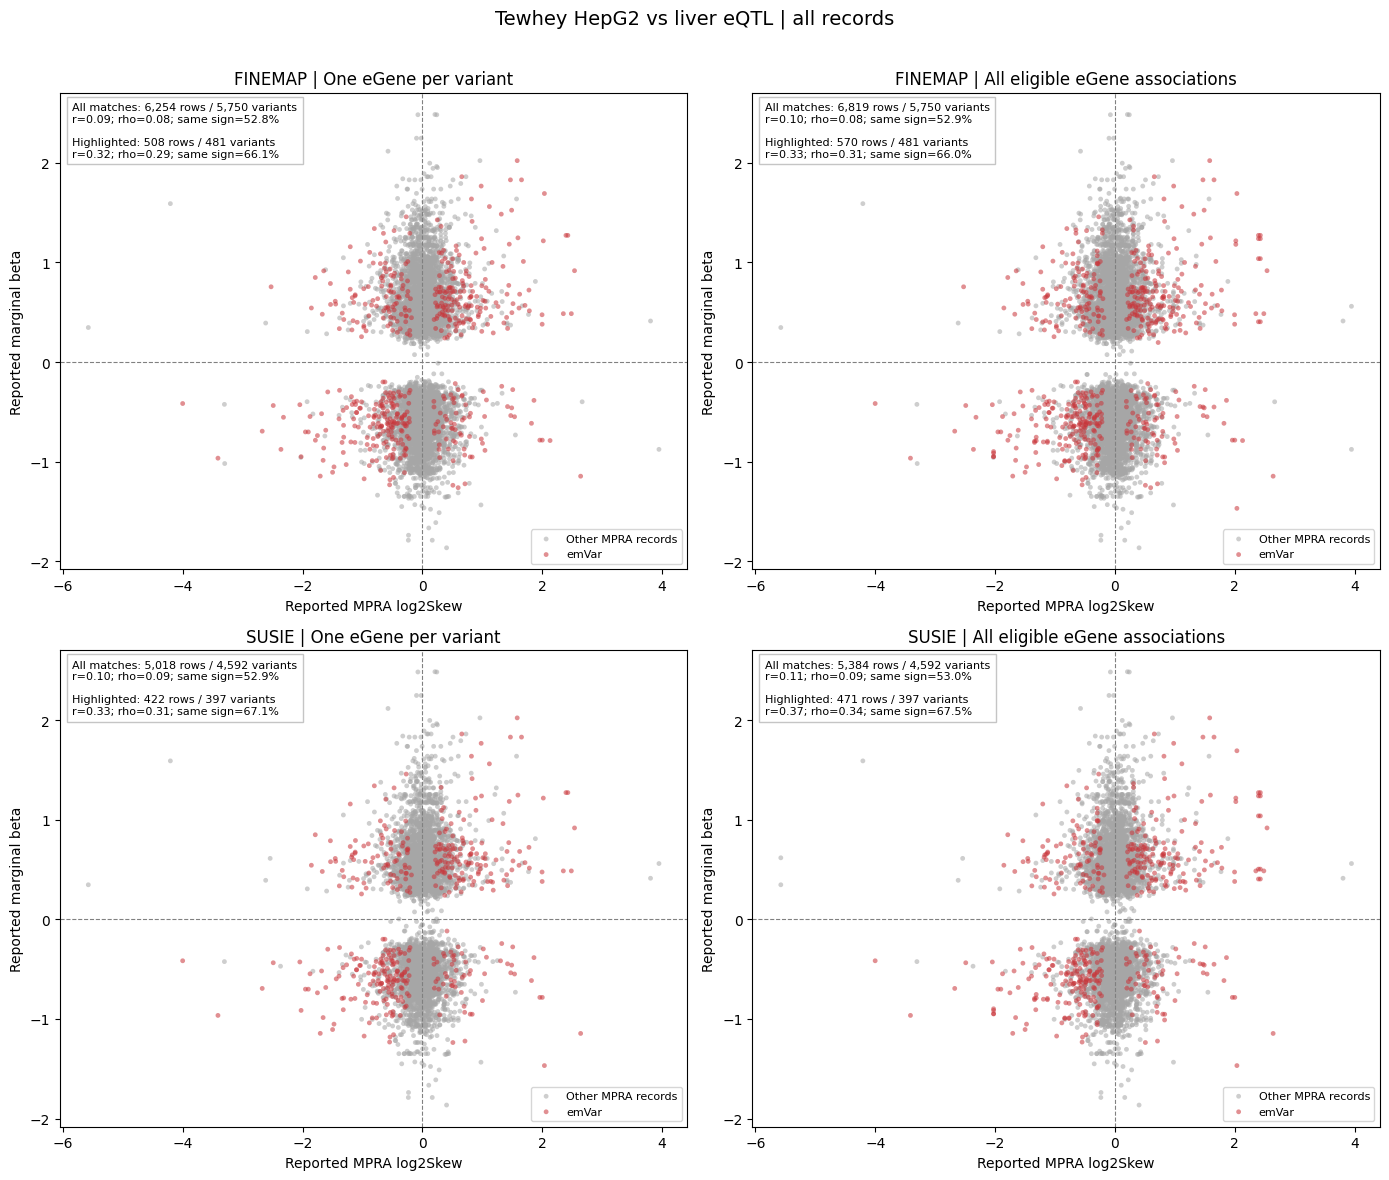

{'dataset': 'tewhey',
 'inputs': [{'file': 'GTEx_Liver_eQTLs.signif_pairs.tsv.gz',
   'sha256': '2f1830f56eb424c81f52de4f0ea7f9d0d583970c6d236e1aeb085c8d4f36d165',
   'bytes': 18102553,
   'source': 'https://www.synapse.org/Synapse:syn69058503.1',
   'version': '1'},
  {'file': 'gtex_finemap_eqtls_pip01_with_spdi.csv',
   'sha256': '677ad8151b8fdbecfc376721b5e7cda0f6f78cb7939692a6091d4fc49faa9c68',
   'bytes': 371054475,
   'source': None,
   'note': 'Original download and SPDI conversion provenance not recovered.'},
  {'file': 'hepg2_combined_final_processed.tsv.gz',
   'sha256': 'eaf0f4d33e5f9371876957c76e76354dae8c91d0c7d8e0b27301422503330c9a',
   'bytes': 40276308,
   'source': None,
   'note': 'Original download, processing and emVar definition not recovered.'}],
 'audit': {'eqtl': {'eqtl_inputs': [{'dataset': 'GTEx',
     'rows': 931743,
     'unique_variants': 584404,
     'unique_variant_gene_pairs': 931743,
     'allele_metadata_counts': '{"matches_spdi_order": 931743}'},
    

Saved 2 PNG files; summaries and provenance are retained in this notebook.


In [4]:
plot_files = plot_panels(panels, DATASET, ROOT / 'plots', q_threshold=MPRA_Q_THRESHOLD)
run_metadata = describe_run(DATA_DIR, DATASET,
                            {'eqtl': eqtl_audit, 'mpra': mpra_audit},
                            PIP_THRESHOLD, MPRA_Q_THRESHOLD)
display(run_metadata)
print(f'Saved {len(plot_files)} PNG files; summaries and provenance are retained in this notebook.')

## Interpretation and limitations

The previous analysis showed stronger descriptive correlations in emVar subsets overlapping fine-mapped eQTLs than in the full GTEx comparison. The results above should be interpreted alongside the different coverage and selection rules.

Neither comparison establishes causality or predictive performance. Source effect-direction definitions and the missing preprocessing provenance require follow-up. Duplicate records are intentionally retained and counted; a variant-level aggregation or clustered inference would be a separate, explicitly specified analysis.